In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [18]:
img = cv2.imread("sift3.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img = img.astype(np.float32)

In [19]:
# creating scale space
s = 3
num_images = s + 3
k = 2 ** (1/s)
octave_wise_sigmas = {}
sigma_initial = 1.6
num_octaves = 7

octave_wise_sigmas = {}
for o in range(num_octaves):          # o = 0,1,2,...
    sigmas = [sigma_initial * (k ** i) for i in range(num_images)]
    octave_wise_sigmas[f"octave_{o}"] = sigmas


In [20]:
octave_wise_sigmas

{'octave_0': [1.6,
  2.015873679831797,
  2.5398416831491195,
  3.2,
  4.031747359663594,
  5.079683366298239],
 'octave_1': [1.6,
  2.015873679831797,
  2.5398416831491195,
  3.2,
  4.031747359663594,
  5.079683366298239],
 'octave_2': [1.6,
  2.015873679831797,
  2.5398416831491195,
  3.2,
  4.031747359663594,
  5.079683366298239],
 'octave_3': [1.6,
  2.015873679831797,
  2.5398416831491195,
  3.2,
  4.031747359663594,
  5.079683366298239],
 'octave_4': [1.6,
  2.015873679831797,
  2.5398416831491195,
  3.2,
  4.031747359663594,
  5.079683366298239],
 'octave_5': [1.6,
  2.015873679831797,
  2.5398416831491195,
  3.2,
  4.031747359663594,
  5.079683366298239],
 'octave_6': [1.6,
  2.015873679831797,
  2.5398416831491195,
  3.2,
  4.031747359663594,
  5.079683366298239]}

In [21]:
def gaussian_kernel(size, sigma):
    assert size % 2 == 1, "Kernel size must be odd"
    k = size // 2
    x, y = np.meshgrid(np.arange(-k, k + 1), np.arange(-k, k + 1))
    kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    kernel /= kernel.sum()
    return kernel.astype(np.float32)

In [22]:
kernel_size_init = int(2 * np.ceil(3 * sigma_initial) + 1)
gk_initial = gaussian_kernel(kernel_size_init, sigma_initial)
o_gk_img_initial = img.copy()

# applying initial kernel to image
K = gk_initial.shape[0]
for i in range(0, img.shape[0] - K + 1):
    for j in range(0, img.shape[1] - K + 1):
        img_slice = img[i:i+K, j:j+K]
        o_gk_img_initial[i + K//2, j + K//2] = np.sum(gk_initial * img_slice)

In [23]:
def get_del_sigma(sigma1, sigma2):
    return np.sqrt(sigma2**2 - sigma1**2)

def create_dogs_octave(octave_sigmas, o_gk_img_initial, octave_number):

    for a in range(octave_number):
        o_gk_img_initial = cv2.resize(o_gk_img_initial, (0, 0), fx=.5, fy=.5, interpolation=cv2.INTER_AREA)

    # starting out with gaussian applied iamg 
    gk_applied_imgs = [o_gk_img_initial]
    for k in range(len(octave_sigmas)-1):
        # going over every sigma in the sigma list for that octave
        # finding out the kernel size for this specific sigma
        del_sigma = get_del_sigma(octave_sigmas[k], octave_sigmas[k+1])
        kernel_size = int(2 * np.ceil(3*del_sigma)+1)
        gk = gaussian_kernel(kernel_size, del_sigma)
        o_gk_img = gk_applied_imgs[-1].copy()

        K = gk.shape[0]
        for i in range(0, gk_applied_imgs[-1].shape[0] - K + 1):
            for j in range(0, gk_applied_imgs[-1].shape[1] - K + 1):
                img_slice = gk_applied_imgs[-1][i:i+K, j:j+K]
                o_gk_img[i + K//2, j + K//2] = np.sum(gk * img_slice)

        gk_applied_imgs.append(o_gk_img)
    dogs = []
    for i in range(1, len(gk_applied_imgs)):
        dogs.append(gk_applied_imgs[i] - gk_applied_imgs[i-1])
    return dogs, gk_applied_imgs

def hessian_test(candidate_slice, kernel_dim=3, r=10):

    assert candidate_slice.shape == (3, 3)
    
    slice_center_row = candidate_slice[candidate_slice.shape[0]//2]
    del_square_x = slice_center_row[kernel_dim-1] - 2 * slice_center_row[kernel_dim//2] + slice_center_row[0]

    slice_center_col = candidate_slice[:, kernel_dim//2]
    del_square_y = slice_center_col[kernel_dim-1] - 2 * slice_center_col[kernel_dim//2] + slice_center_col[0]

    del_square_xy = (
    candidate_slice[2, 2]
    - candidate_slice[2, 0]
    - candidate_slice[0, 2]
    + candidate_slice[0, 0]
    ) * 0.25

    det = (del_square_x*del_square_y - del_square_xy**2)
    if det <= 0:
        return False
    if ((del_square_x + del_square_y)**2) / det > (((r + 1)**2) / r):
        return False
    return True

def keypoint_check_condition(slice_3d_img):
    assert slice_3d_img.shape == (3,3,3)
    x = slice_3d_img.flatten()
    center_pxl_index = x.shape[0]//2
    center_pxl_val = x[center_pxl_index] # getting the center pxl value in the 3d slice
    y = np.delete(x, center_pxl_index)
    if np.all(center_pxl_val > y) or np.all(center_pxl_val < y):
        return True
    else:
        return False

def get_gradient(img, sigma):
    img = np.array(img)
    radius = int(3 * 1.5 * sigma)
    i, j = img.shape[0]//2, img.shape[1]//2
    circular_region = img[i-radius:i+radius, j-radius: j+radius]

    gradients = {}
    
    curr_circle_indices = []
    for p in range(circular_region.shape[0]):
        for q in range(circular_region.shape[1]):
            if p**2 + q**2 <= radius **2:
                # calculate gradient magnitude
                dx = circular_region[p, q + 1] - circular_region[p, q-1]
                dy = circular_region[p+1, q] - circular_region[p-1, q]
                gradient_mag = np.sqrt(dx**2 + dy**2)
                # calculate gradient direction
                gradient_angle = np.arctan2(dy, dx)
                gradients[f"{p},{q}"] = [gradient_mag, gradient_angle]
    return gradients

                

In [24]:
dogs_all_octaves = []
gk_applied_all_imgs = []
for i in range(1, num_octaves):
    dogs_octave, gk_applied_imgs_octave = create_dogs_octave(octave_wise_sigmas[f"octave_{i}"], o_gk_img_initial, i)
    dogs_all_octaves.append(dogs_octave)
    gk_applied_all_imgs.append(gk_applied_imgs_octave)

keypt_drawn_output_images_all_octaves = []
keypoints_all_octaves = []
for z in range(num_octaves-1):
    # skip first and last dog
    kernel_dim = 3
    keypoints_curr_octave = []
    output_imgs_curr_octave = []
    dogs_octave = dogs_all_octaves[z]
    # for all dogs in the current octave
    for k in range(1, len(dogs_octave)-1):
        # get the stacked dogs for the later calculatoin of the cube space for gradient calculation
        dogs_3d = np.stack([dogs_octave[k-1], dogs_octave[k], dogs_octave[k+1]])
        output_img = dogs_octave[k].copy()

        # for every cube space in 3d dogs stack
        for i in range(dogs_3d.shape[1]-kernel_dim):
            for j in range(dogs_3d.shape[2]-kernel_dim):
                dogs_3d_slice = dogs_3d[:, i:i+kernel_dim, j:j+kernel_dim]
                # contrast thresholding with > 8 is since our images are in 0-255 scale
                if keypoint_check_condition(dogs_3d_slice) and abs(dogs_octave[k][i+1, j+1]) > 3:
                    if hessian_test(dogs_octave[k][i:i+kernel_dim, j:j+kernel_dim]):
                        keypoints_curr_octave.append([i+kernel_dim//2, j+kernel_dim//2])
                        output_img = cv2.circle(output_img, (j+kernel_dim//2, i+kernel_dim//2), 5,  (255, 0, 0), 1)
                        gradients =  get_gradient(gk_applied_all_imgs[z][k], octave_wise_sigmas[f'octave_{k}'][k])
                        output_img = output_img = cv2.circle(output_img, (j+kernel_dim//2, i+kernel_dim//2), 5,  (255, 0, 0), 1)
        output_imgs_curr_octave.append(output_img)

    keypt_drawn_output_images_all_octaves.append(output_imgs_curr_octave)
    keypoints_all_octaves.append(keypoints_curr_octave)

In [25]:
len(gk_applied_all_imgs[0][0].shape)

2

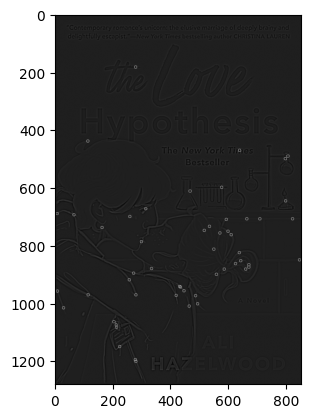

In [26]:
plt.imshow(keypt_drawn_output_images_all_octaves[0][0], cmap="grey")

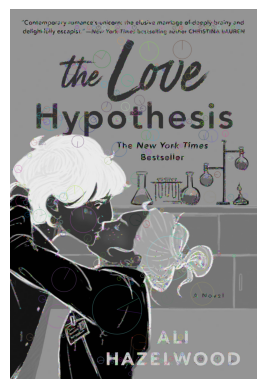

num keypoints: 8015
descriptor shape: (8015, 128)


In [27]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

sift = cv2.SIFT_create()

img_uint8 = (img * 255).astype(np.uint8)

kp, des = sift.detectAndCompute(img_uint8, None)

img_kp = cv2.drawKeypoints(
    img_uint8,
    kp,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.imshow(img_kp)
plt.axis("off")
plt.show()

print("num keypoints:", len(kp))
print("descriptor shape:", des.shape)

In [28]:
print(img.dtype)
print(img.shape)

float32
(2560, 1706)
